# Lab 03: How to give an agent memory

**CPU | API key: `OPENAI_API_KEY` (most of Part A runs without one) | Follows: Day 1 D1-M05, steps 5.1 to 5.6 (slides 145–180)**

## Goal

The agent from Lab 01 forgets everything between calls: ask it a follow-up and it has no idea who "she" is. In this
lab you give the copilot memory within a conversation and across a restart, then keep long conversations short
without losing the facts that matter. The moment that teaches it: on the same seven turns, the trimmed copilot answers
turn 7 politely and without an error, and it is wrong, because the invoice total and the rep from turn 2 are no longer
in what it is sent. Summarising kept the facts but used the most tokens; the fix that holds is to keep the case facts
in the agent's state, where no trim can reach them.

## What you will learn

- Why a chat model forgets between calls, and how a checkpointer and a `thread_id` give an agent memory within one
  conversation.
- How to keep a conversation across a restart with `SqliteSaver`.
- What full history, trimming and summarising cost per turn, and what each one can lose, measured on the same seven
  turns.
- The difference between trimming the saved thread and trimming only what the model is sent.
- How to keep facts that must never be lost in the agent's state instead of the message history.
- How to test any memory setting: ask late for a fact stated early.

| Part | What you do | Calls to OpenAI |
|---|---|---|
| A | Ask a follow-up with nothing shared, then resend the conversation by hand; watch what the model receives on a thread, trim a list of messages, delete one exchange | 3, then 0 (a scripted stand-in model) |
| B | Save a thread to a SQLite file and read it back from a new connection | 2 |
| C | Run seven turns under full history, two kinds of trimming and summarising; log and chart the input tokens | about 40 (ours: 41) |
| D | Ask for an early fact at turn 7, read the saved summary, then keep the case facts in state | 8 to 10 (ours: 8) |
| E | Choose a memory strategy for three conversations | 0 |

The whole lab uses about 31,000 input tokens: well under one US cent with `gpt-4o-mini`.

## The first two cells

These are the same two cells that open Lab 00, which explains each line. **Setup** finds the repository folder (on
Colab it copies the repository and installs the packages first). **Config** reads the model names from `models.env`
and finds your key without printing it.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


⚠️ On Colab, run the setup cell first in a fresh session. If another cell loaded the old `openai` package before the
install, Part A fails with `ImportError: cannot import name ... from 'openai...'`; use **Runtime → Restart session**
and run from the top.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


Part A's first three calls and Parts B to D call `CHAT_MODEL`; the rest of Part A uses a scripted stand-in and needs
no key.

The picture shows one turn on a thread. The **checkpointer** loads the thread's earlier messages before the model is
called and saves the new ones afterwards, under the conversation's `thread_id`. Between the two, middleware can
decide what the model is actually sent: everything (full history), only the newest messages (trim) or a summary plus
the newest messages (summarise), and facts kept outside the messages can be added to the prompt. This lab builds each
piece in that order.

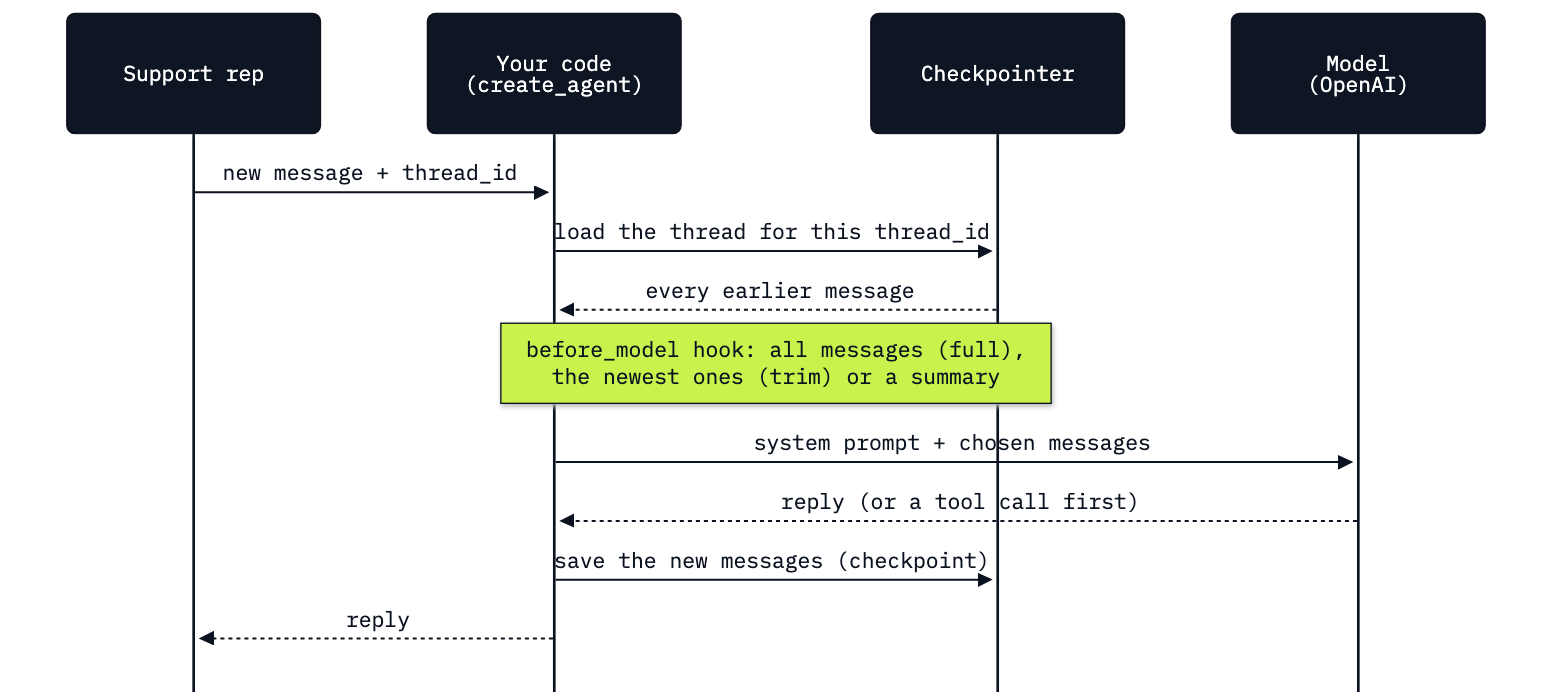

In [3]:
from IPython.display import Image
Image(filename=ROOT / "03_Thread_Memory_Three_Settings" / "resources" / "lab03_thread_turn.png", width=760)

---

## Part A: What the model receives

An OpenAI request is stateless: the model sees only the messages in that request. Try it with two calls to the real
model (`CHAT_MODEL`, built by `chat_model()` from `shared/settings.py`, as Lab 01 built it by hand). The first tells
it about a customer; the second asks a follow-up and shares nothing with the first.


In [4]:
from shared.settings import chat_model

model = chat_model(settings)
SHORT_SYSTEM = ("system", "You help Chinook support reps. Keep answers short.")

first = model.invoke([SHORT_SYSTEM, ("user", "Hi, I have Helena Holý on email. She has 7 invoices.")])
print("call 1:", first.text)
second = model.invoke([SHORT_SYSTEM, ("user", "What was her name again?")])
print("call 2:", second.text)

call 1: Please provide more details about the invoices or how you need assistance with Helena Holý.


call 2: Could you provide more context or details? That would help me assist you better.


When we ran it (`gpt-4o-mini`, 11 Oct 2026), call 1 asked for more details about Helena's invoices, and call 2
answered *Could you provide more context or details? That would help me assist you better.* The model had no idea
who "her" was: call 2 held the system prompt and one question, and no customer. Nothing failed, and nothing was
remembered.

The fix is to send the earlier messages again. Do it by hand first: keep the conversation in a list, add the
model's first reply and the follow-up, and send the whole list.

In [5]:
conversation = [
    SHORT_SYSTEM,
    ("user", "Hi, I have Helena Holý on email. She has 7 invoices."),
    first,                                   # the model's own reply from call 1
    ("user", "What was her name again?"),
]
third = model.invoke(conversation)
print(len(conversation), "messages sent")
print("call 3:", third.text)

4 messages sent
call 3: Her name is Helena Holý.


Four messages sent, and call 3 answered *Her name is Helena Holý.* (`gpt-4o-mini`, 11 Oct 2026). The model is the
same and so is the question; only the list changed.

That is all memory within a conversation is: your code keeps the messages and sends them again with every call. It
works, but your code now owns the list for every conversation, and the list grows with every turn. A **checkpointer**
does the keeping for you: it saves each conversation's messages under a name and loads them before each call.

To see exactly what is sent, the rest of this part uses a stand-in for the model: `shared/scripted.py`, a scripted model that
returns replies written in advance and records the types of the messages it receives. It makes no API call, and the cell that
creates it prints the label **SCRIPTED MODEL · NO API CALL**, which covers every output from here to the end of Part A. Its replies mean nothing; what it received is the
lesson.

In [6]:
from langchain.agents import create_agent
from langchain_core.messages import AIMessage
from langgraph.checkpoint.memory import InMemorySaver
from shared.scripted import scripted

stand_in = scripted(*[AIMessage(f"(reply {n})") for n in range(1, 11)])
print("SCRIPTED MODEL · NO API CALL |", type(stand_in).__name__, "| calls recorded so far:", stand_in.sent)

SCRIPTED MODEL · NO API CALL | ScriptedModel | calls recorded so far: []


Now an agent with two new pieces:

- `checkpointer=InMemorySaver()` saves the agent's state after every step and loads it at the next turn. `InMemorySaver`
  keeps it in this Python process; Part B keeps it in a file.
- `thread_id` names the conversation. It goes in the config you pass to `invoke`, under `"configurable"`. Same id,
  same history.

There are no tools, so each turn is one model call.

In [7]:
agent = create_agent(
    stand_in,
    tools=[],
    system_prompt="You help Chinook support reps.",
    checkpointer=InMemorySaver(),
)
helena = {"configurable": {"thread_id": "case-helena-01"}}
print(helena)

{'configurable': {'thread_id': 'case-helena-01'}}


Send the first turn on that thread and print the types of the messages the model received.

In [8]:
agent.invoke({"messages": [("user", "Hi, I have Helena Holý on email.")]}, helena)
print("turn 1: the model received", stand_in.sent[-1])

turn 1: the model received ['system', 'human']


Two messages: the system prompt and the rep's message (`human` is LangChain's name for the user role).

Predict: your code sends only one new message on turn 2 and one on turn 3. How many messages does the model receive
each time?

In [9]:
agent.invoke({"messages": [("user", "She has 7 invoices.")]}, helena)
print("turn 2: the model received", stand_in.sent[-1])

agent.invoke({"messages": [("user", "What was her name again?")]}, helena)
print("turn 3: the model received", stand_in.sent[-1])

turn 2: the model received ['system', 'human', 'ai', 'human']
turn 3: the model received ['system', 'human', 'ai', 'human', 'ai', 'human']


Four, then six. The checkpointer loaded the earlier turns, and the agent sent them again before the new message:
turn 3 carries both earlier questions and both earlier replies. A real model could answer "What was her name
again?" only because turn 1 is in the request.

Now the same question on a **new** `thread_id`, with the same agent.

In [10]:
puja = {"configurable": {"thread_id": "case-puja-01"}}
agent.invoke({"messages": [("user", "What was her name again?")]}, puja)
print("new thread: the model received", stand_in.sent[-1])

new thread: the model received ['system', 'human']


Two messages again. Nothing from `case-helena-01` reached this call: two cases, two threads, and neither sees the
other's messages. That is what you want when a rep switches customers.

The checkpointer keeps the thread outside the model. `get_state` reads what it saved for one `thread_id`.

In [11]:
saved = agent.get_state(helena).values["messages"]
for number, message in enumerate(saved):
    print(number, f"{message.type:5} | {message.text}")

0 human | Hi, I have Helena Holý on email.
1 ai    | (reply 1)
2 human | She has 7 invoices.
3 ai    | (reply 2)
4 human | What was her name again?
5 ai    | (reply 3)


Six messages: three from the rep, three replies. The system prompt is not in the saved thread. `create_agent` adds it
to the front of every model call, so changing the prompt changes every later turn of every thread.

### Trimming a list of messages

A thread grows every turn, and you pay for every input token every turn. The cheapest control is to **trim**: drop
the oldest messages before each call. `trim_messages` from `langchain_core` does it. Try it on an
eight-message history; build that history first.

In [12]:
from langchain_core.messages import HumanMessage, SystemMessage, trim_messages

history = [
    SystemMessage("You help Chinook support reps."),
    HumanMessage("Customer is Helena Holý."), AIMessage("Noted."),
    HumanMessage("7 invoices, $49.62, rep Steve Johnson."), AIMessage("Noted."),
    HumanMessage("She wants a replacement disc."), AIMessage("Ticket 01, waiting on a photo."),
    HumanMessage("What is her invoice total?"),
]
print(len(history), "messages")

8 messages


The arguments:

- `strategy="last"` keeps the newest messages.
- `token_counter=len` counts **messages**, not tokens: each message counts as one, so `max_tokens=5` means "at most
  five messages". With a real tokenizer the same argument would be a token budget.
- `start_on="human"` makes the kept window start with a rep's message, never with a reply whose question was cut off.
- `include_system=True` always keeps the system message at the front.

Predict: which messages survive? This runs on your machine and calls no model.

In [13]:
kept = trim_messages(history, strategy="last", token_counter=len, max_tokens=5,
                     start_on="human", include_system=True)
for message in kept:
    print(f"{message.type:6} | {message.content}")

system | You help Chinook support reps.
human  | She wants a replacement disc.
ai     | Ticket 01, waiting on a photo.
human  | What is her invoice total?


Four messages, although five were allowed. The newest five were the system message, *Noted.*, and the last three.
`start_on="human"` dropped the *Noted.* because it would have started the window with a reply. Run it without
`start_on` to see that message come back.

In [14]:
kept_without_start = trim_messages(history, strategy="last", token_counter=len, max_tokens=5, include_system=True)
for message in kept_without_start:
    print(f"{message.type:6} | {message.content}")

system | You help Chinook support reps.
ai     | Noted.
human  | She wants a replacement disc.
ai     | Ticket 01, waiting on a photo.
human  | What is her invoice total?


Five messages, starting with a reply to a question the model can no longer see. Keep `start_on="human"`.

Now read the four kept messages as the model would. The last question asks for the invoice total.

| Message in the history | Kept? |
|---|---|
| You help Chinook support reps. | yes |
| Customer is Helena Holý. | dropped |
| Noted. | dropped |
| 7 invoices, $49.62, rep Steve Johnson. | dropped |
| Noted. | dropped |
| She wants a replacement disc. | yes |
| Ticket 01, waiting on a photo. | yes |
| What is her invoice total? | yes |

The message that held the total was dropped. Nothing failed: `trim_messages` did what it was told, the list is shorter,
and a model would answer from it without any error. This is the risk of trimming, and Part D measures it on a real
thread.

### Trim by tokens

Counting messages keeps the example easy to follow, but a context window and a bill are measured in tokens, and one
message can be 5 tokens or 5,000. In practice you trim to a token budget. `count_tokens_approximately` from
`langchain_core` estimates a message's tokens from its length, with no tokenizer to download; an exact count needs the
model's tokenizer (`tiktoken` for OpenAI), and an estimate is enough to set a budget.

In [15]:
from langchain_core.messages.utils import count_tokens_approximately

for message in history:
    print(f"{count_tokens_approximately([message]):3} tokens | {message.content}")
print("total:", count_tokens_approximately(history))

 12 tokens | You help Chinook support reps.
 10 tokens | Customer is Helena Holý.
  7 tokens | Noted.
 14 tokens | 7 invoices, $49.62, rep Steve Johnson.
  7 tokens | Noted.
 12 tokens | She wants a replacement disc.
 13 tokens | Ticket 01, waiting on a photo.
 11 tokens | What is her invoice total?
total: 86


The estimate gives each *Noted.* 7 tokens and the message with the facts 14; the whole history is 86. Now trim the same history to a budget of 60 tokens, then 70. Predict: does the message with the total come
back at 70?

In [16]:
for budget in (60, 70):
    kept = trim_messages(history, strategy="last", token_counter=count_tokens_approximately,
                         max_tokens=budget, start_on="human", include_system=True)
    print(f"budget {budget}: {len(kept)} messages kept")
    for message in kept:
        print(f"   {message.type:6} | {message.content}")

budget 60: 4 messages kept
   system | You help Chinook support reps.
   human  | She wants a replacement disc.
   ai     | Ticket 01, waiting on a photo.
   human  | What is her invoice total?
budget 70: 6 messages kept
   system | You help Chinook support reps.
   human  | 7 invoices, $49.62, rep Steve Johnson.
   ai     | Noted.
   human  | She wants a replacement disc.
   ai     | Ticket 01, waiting on a photo.
   human  | What is her invoice total?


At 60 tokens the result is the same four messages as the message count gave. At 70 the window reaches back to
*7 invoices, $49.62, rep Steve Johnson.*, because the short *Noted.* replies cost little. A token budget keeps more
short messages and fewer long ones, which a message count cannot do. The rest of the lab counts messages again, to
keep the numbers easy to follow.

### Delete one exchange (optional)

A third control is to **delete** exactly the messages you name, with `RemoveMessage(id=...)`. Every saved
message has an `id`. Delete the rep's second message and its reply from `case-helena-01` (numbers 2 and 3 in the
saved thread above). `update_state` writes the change into the checkpoint as if a step of the agent had made it.

In [17]:
from langchain_core.messages import RemoveMessage

agent.update_state(helena, {"messages": [RemoveMessage(id=saved[2].id), RemoveMessage(id=saved[3].id)]})
for message in agent.get_state(helena).values["messages"]:
    print(f"{message.type:5} | {message.text}")

human | Hi, I have Helena Holý on email.
ai    | (reply 1)
human | What was her name again?
ai    | (reply 3)


The thread now holds four messages; *She has 7 invoices.* and its reply are gone from the saved thread. Ask the next
turn and look at what the model receives.

In [18]:
agent.invoke({"messages": [("user", "How many invoices does she have?")]}, helena)
print("the model received", stand_in.sent[-1])

the model received ['system', 'human', 'ai', 'human', 'ai', 'human']


Six messages: the system prompt, the four that remain and the new question. The 7 is not among them, so a real model
could not answer. Deleting is precise, which makes it useful for removing something on purpose (a message with
personal data, a wrong instruction), and the deleted fact is gone for every later turn.

### Checkpoint A

After its first three calls this part used the scripted model, so those rows match ours exactly. The first three
calls are real model replies; check what they show, not our wording.

| You should see | Value |
|---|---|
| The follow-up with nothing shared | the model does not know who "her" is (ours, `gpt-4o-mini`, 11 Oct 2026: it asked for more context) |
| The list resent by hand | 4 messages sent; the reply names Helena Holý |
| Turns 1, 2, 3 on `case-helena-01` | 2, 4 and 6 messages: `system`, `human`, then one `ai`, `human` pair per earlier turn |
| The same question on `case-puja-01` | 2 messages |
| The saved thread | 6 messages, no system prompt |
| `trim_messages` with `max_tokens=5` and `start_on="human"` | 4 messages kept: the system message, *She wants a replacement disc.*, *Ticket 01, waiting on a photo.*, *What is her invoice total?* |
| Without `start_on` | 5 messages, the second one *Noted.* |
| Approximate tokens | 86 for the eight messages; *Noted.* 7, the turn-2 message 14 |
| Token budgets | 60 keeps 4 messages (the same as `max_tokens=5` messages); 70 keeps 6, including *7 invoices, $49.62, rep Steve Johnson.* |
| After deleting messages 2 and 3 | 4 messages saved; the next turn sends 6 |

---

## Part B: A thread that survives a restart

`InMemorySaver` keeps threads in this Python process. Restart the kernel and they are gone. You can see the same thing
without a restart: a new `InMemorySaver` is an empty store, which is what a restarted kernel gives you. Ask it for
`case-helena-01`.

In [19]:
restarted = create_agent(stand_in, tools=[], system_prompt="You help Chinook support reps.",
                         checkpointer=InMemorySaver())
print("messages saved for case-helena-01:", restarted.get_state(helena).values.get("messages", []))

messages saved for case-helena-01: []


Nothing. LangGraph has three savers with the same interface: `InMemorySaver` for notebooks and tests, `SqliteSaver`
for one machine (one file), `PostgresSaver` for several servers sharing a database. Only the `checkpointer=` argument
changes.

`SqliteSaver` comes from the `langgraph-checkpoint-sqlite` package and writes to a SQLite file. We put the file in a
new temporary folder so the lab leaves nothing behind in the repository. From here on, the cells call the real chat
model again, built by `chat_model()` as at the start of Part A.

In [20]:
import sqlite3
import tempfile
from pathlib import Path

from langgraph.checkpoint.sqlite import SqliteSaver
from shared.settings import chat_model

db_file = Path(tempfile.mkdtemp()) / "threads.sqlite"
SHORT_PROMPT = "You help Chinook support reps. Keep answers short."
print("thread file:", db_file.name)

thread file: threads.sqlite


The first "process": open a connection to the file, build an agent on it, send one turn on `case-puja-01`, close the
connection. `check_same_thread=False` lets LangGraph use the connection from its worker threads; without it, `sqlite3`
refuses with a `ProgrammingError`.

In [21]:
conn = sqlite3.connect(db_file, check_same_thread=False)
agent_1 = create_agent(chat_model(settings), tools=[], system_prompt=SHORT_PROMPT,
                       checkpointer=SqliteSaver(conn))
result = agent_1.invoke({"messages": [("user", "The customer on this ticket is Puja Srivastava.")]}, puja)
print(result["messages"][-1].text)
conn.close()

Got it! How can I assist you with Puja Srivastava's ticket?


The connection is closed and `agent_1` cannot be used any more. The second "process" opens a **new** connection to the
same file and builds a **new** agent. Predict: does it know the customer?

In [22]:
conn = sqlite3.connect(db_file, check_same_thread=False)
agent_2 = create_agent(chat_model(settings), tools=[], system_prompt=SHORT_PROMPT,
                       checkpointer=SqliteSaver(conn))
result = agent_2.invoke({"messages": [("user", "Which customer am I working on?")]}, puja)
print(result["messages"][-1].text)

You're working on a ticket for Puja Srivastava.


When we ran it (`gpt-4o-mini`, 11 Oct 2026), the first agent replied *Got it! How can I assist you with Puja Srivastava's ticket?* and the second *You're working on a ticket for Puja Srivastava.* Nothing was held in Python between the two agents: the new connection read the thread back from the file,
and the model received the first exchange again.

The file is an ordinary SQLite database. Count the checkpoints saved for this thread.

In [23]:
count = conn.execute("SELECT COUNT(*) FROM checkpoints WHERE thread_id = 'case-puja-01'").fetchone()[0]
print("checkpoints saved for case-puja-01:", count)

checkpoints saved for case-puja-01: 6


Six checkpoints for two turns. A checkpoint is a snapshot of the state after a step, not one per
turn. `get_state_history` lists them, newest first, with the step number, what produced it and how many messages the
state held.

In [24]:
for snapshot in agent_2.get_state_history(puja):
    print(f"step {snapshot.metadata['step']:2}  {snapshot.metadata['source']:5}  "
          f"{len(snapshot.values['messages'])} messages  next: {snapshot.next}")
conn.close()

step  4  loop   4 messages  next: ()
step  3  loop   3 messages  next: ('model',)
step  2  input  2 messages  next: ('__start__',)
step  1  loop   2 messages  next: ()
step  0  loop   1 messages  next: ('model',)
step -1  input  0 messages  next: ('__start__',)


Three per turn: the `input` checkpoint before the new message is applied, a `loop` checkpoint with the message added
and the model next, and a `loop` checkpoint after the model's reply. This history is what lets LangGraph resume a run
part-way, which the approval lab (Lab 08) relies on.

### Checkpoint B

| You should see | Value from our run (`gpt-4o-mini`, 11 Oct 2026) |
|---|---|
| The new `InMemorySaver` | `[]`: no messages for `case-helena-01` |
| The second connection's reply | names Puja Srivastava (ours: *You're working on a ticket for Puja Srivastava.*) |
| Checkpoints for `case-puja-01` | 6 |
| The history | steps 4 to -1, three per turn; 4 messages in the newest |

---

## Part C: Seven turns under four memory settings

Now the copilot itself: the prompt file v1 and the `get_policy` tool, on one thread of seven turns. A rep is
handling Helena Holý's emails. Turn 2 states two facts: 7 invoices totalling $49.62, and her assigned rep is
Steve Johnson (both match `data/chinook.db`, which Lab 00 checked). Turn 7 asks for them back.

The system prompt is the versioned file `copilot_system_v1.md` from `shared/prompts/`, which Lab 02 tested against a weak prompt. Its first lines are
a comment with the version and date, which the model does not need, so we drop them.

In [25]:
prompt_file = ROOT / "shared" / "prompts" / "copilot_system_v1.md"
SYSTEM_PROMPT = prompt_file.read_text(encoding="utf-8").split("-->", 1)[1].strip()
print(SYSTEM_PROMPT[:240], "...")

# Identity
You are the Chinook support copilot. You help Chinook's support representatives (reps) answer customer emails. You talk to the rep, not to the customer.

# Instructions
- Call get_policy before you answer any question about shop  ...


The tool is the one you wrote in Lab 01, unchanged.

In [26]:
from langchain.tools import tool

CORPUS = ROOT / "data" / "corpus"
POLICIES = sorted(path.stem.removeprefix("policy_") for path in CORPUS.glob("policy_*.md"))

@tool(parse_docstring=True)
def get_policy(name: str) -> str:
    """Return the full text of one Chinook support policy.

    Call it before answering any question about shop rules.

    Args:
        name: Policy name, e.g. "refunds" or "escalations".
    """
    path = CORPUS / f"policy_{name}.md"
    if not path.exists():
        known = ", ".join(POLICIES)
        return f"No policy named {name!r}. Known: {known}."
    return path.read_text(encoding="utf-8")

print(get_policy.name, "|", len(POLICIES), "policies")

get_policy | 20 policies


The seven turns. Turn 2 states the facts; turn 7 asks for them back.

In [27]:
TURNS = [
    "Hi, I'm handling Helena Holý's emails today.",
    "For context: she has 7 invoices totalling $49.62, and her assigned rep is Steve Johnson.",
    "She says the Kind of Blue sleeve had a different disc inside. What does policy say?",
    "She would prefer a replacement, not a refund. Is that allowed?",
    "How long until she gets a decision?",
    "Draft a two-sentence reply I can send her.",
    "Before I close the ticket: what is her invoice total, and who is her assigned rep?",
]
for number, text in enumerate(TURNS, start=1):
    print(number, text)

1 Hi, I'm handling Helena Holý's emails today.
2 For context: she has 7 invoices totalling $49.62, and her assigned rep is Steve Johnson.
3 She says the Kind of Blue sleeve had a different disc inside. What does policy say?
4 She would prefer a replacement, not a refund. Is that allowed?
5 How long until she gets a decision?
6 Draft a two-sentence reply I can send her.
7 Before I close the ticket: what is her invoice total, and who is her assigned rep?


### Log every model call

One turn can make several model calls (a tool call, then the reply), and the summarising setting adds calls of its
own. To compare the settings we record, for every call: who made it, how many messages it was sent and its input
tokens.

LangChain reports each call to **callback handlers** you pass in the config. A handler is a class with methods named
after events: `on_chat_model_start` receives the messages about to be sent, and `on_llm_end` receives the response,
with its `usage_metadata`. We also keep `cache_read`: the input tokens OpenAI served from its prompt cache, billed at
half price for `gpt-4o-mini`. In production, a tracing tool such as LangSmith records the same data for you; Lab 10 keeps the same ledger with a callback and prices it. The summariser marks its own calls with `lc_source: "summarization"` in their metadata;
we use that to tell its calls from the agent's.

In [28]:
from langchain_core.callbacks import BaseCallbackHandler

class CallLog(BaseCallbackHandler):
    """Records each model call: who made it, how many messages it sent, its input and cached tokens."""

    def __init__(self):
        self.calls = []

    def on_chat_model_start(self, serialized, messages, *, metadata=None, **kwargs):
        caller = "summariser" if (metadata or {}).get("lc_source") == "summarization" else "agent"
        self.calls.append({"caller": caller, "sent": len(messages[0])})

    def on_llm_end(self, response, **kwargs):
        usage = response.generations[0][0].message.usage_metadata
        self.calls[-1]["input_tokens"] = usage["input_tokens"]
        self.calls[-1]["cached"] = usage.get("input_token_details", {}).get("cache_read", 0)

Try it on one turn before trusting it. The full-history agent is Lab 01's agent plus a checkpointer. The test runs on
its own thread, `log-test`, so it does not count towards the comparison.

In [29]:
full_agent = create_agent(chat_model(settings), tools=[get_policy], system_prompt=SYSTEM_PROMPT,
                          checkpointer=InMemorySaver())
log = CallLog()
result = full_agent.invoke({"messages": [("user", TURNS[0])]},
                           {"configurable": {"thread_id": "log-test"}, "callbacks": [log]})
print(result["messages"][-1].text)
print(log.calls)

Got it! How can I assist you with Helena Holý's emails today?
[{'caller': 'agent', 'sent': 2, 'input_tokens': 459, 'cached': 0}]


One call, sent 2 messages (the system prompt and turn 1), with 459 input tokens when we ran it (`gpt-4o-mini`, 11 Oct 2026). Most of them
are the system prompt and the tool's schema, which are sent with every call.

Now the loop for a whole thread, written once and used for all three settings: send each turn on one `thread_id`
with a fresh log, keep the **first** agent call of each turn (the one that carries the rep's new message), and print a
line per turn with the number of model calls and how many of them were the summariser's.

In [30]:
def run_turns(agent, thread_id, turns):
    """Send each turn on one thread. Return one row per turn: the first call's size, all calls, the reply."""
    rows = []
    for number, text in enumerate(turns, start=1):
        log = CallLog()
        result = agent.invoke({"messages": [("user", text)]},
                              {"configurable": {"thread_id": thread_id}, "callbacks": [log]})
        first = [call for call in log.calls if call["caller"] == "agent"][0]
        by_summariser = len([call for call in log.calls if call["caller"] == "summariser"])
        rows.append({"turn": number, "sent": first["sent"], "first_input": first["input_tokens"],
                     "calls": log.calls, "reply": result["messages"][-1].text})
        print(f"turn {number}: first call sent {first['sent']:2} messages, {first['input_tokens']:4} input tokens"
              f" | model calls: {len(log.calls)} ({by_summariser} by the summariser)")
    return rows

### Full history

Every turn resends every earlier message, including the policy texts that `get_policy` returned. Predict the shape of
the input tokens over seven turns.

In [31]:
full = run_turns(full_agent, "case-helena-full", TURNS)

turn 1: first call sent  2 messages,  459 input tokens | model calls: 1 (0 by the summariser)


turn 2: first call sent  4 messages,  509 input tokens | model calls: 1 (0 by the summariser)


turn 3: first call sent  6 messages,  559 input tokens | model calls: 2 (0 by the summariser)


turn 4: first call sent 10 messages,  692 input tokens | model calls: 2 (0 by the summariser)


turn 5: first call sent 14 messages,  889 input tokens | model calls: 1 (0 by the summariser)


turn 6: first call sent 16 messages,  935 input tokens | model calls: 1 (0 by the summariser)


turn 7: first call sent 18 messages,  991 input tokens | model calls: 1 (0 by the summariser)


When we ran it (`gpt-4o-mini`, 11 Oct 2026), the first call grew every turn, from 2 messages and 459 input tokens to 18 messages
and 991. Turns 3 and 4 each made two model calls because the copilot called `get_policy`: the tool call and the whole
policy text stay in the thread, and every later turn sends them again. This is the cost of memory: with full history,
every turn costs more than the last, and a 40-turn thread would cost far more per turn than a 4-turn one.

When old tool results drive the growth, as the policy texts do here, LangChain's built-in `ContextEditingMiddleware`
with `ClearToolUsesEdit` replaces the older tool results with `[cleared]` in what the model is sent once a request
passes a token threshold (100,000 by default), keeps the newest three, and leaves the saved thread alone; this lab
trims and summarises instead, because those apply to every kind of message.

### Trim inside the agent

Part A trimmed a list by hand. Inside an agent, a `before_model` hook runs before **every** model call, including the
call that follows a tool result. This one keeps up to six messages:

In [32]:
from langchain.agents.middleware import before_model
from langgraph.graph.message import REMOVE_ALL_MESSAGES

@before_model
def keep_recent(state, runtime):
    kept = trim_messages(state["messages"], strategy="last", token_counter=len, max_tokens=6,
                         start_on="human")
    return {"messages": [RemoveMessage(id=REMOVE_ALL_MESSAGES), *kept]}

Two things differ from Part A:

- There is no `include_system`: the system prompt is not in the saved state (Part A showed that), and the agent adds
  it to each call after the hook.
- The hook returns a state update. `RemoveMessage(id=REMOVE_ALL_MESSAGES)` clears the saved messages and the kept
  ones are written back. So the hook trims the **saved thread**, not only this call: what falls off is gone from the
  checkpoint too.

Before it goes into an agent, run the same trim on the full-history thread you just saved, to see what this hook would
keep at that point.

In [33]:
saved_full = full_agent.get_state({"configurable": {"thread_id": "case-helena-full"}}).values["messages"]
window = trim_messages(saved_full, strategy="last", token_counter=len, max_tokens=6, start_on="human")
print(len(saved_full), "messages saved,", len(window), "kept")
for message in window:
    print(f"{message.type:5} | {message.text[:70]!r}")

18 messages saved, 6 kept
human | 'How long until she gets a decision?'
ai    | 'The support policy does not specify a timeframe for decisions. You may'
human | 'Draft a two-sentence reply I can send her.'
ai    | '"Thank you for your patience. I will reach out to our support team for'
human | 'Before I close the ticket: what is her invoice total, and who is her a'
ai    | "Helena's invoice total is $49.62, and her assigned rep is Steve Johnso"


When we ran it (`gpt-4o-mini`, 11 Oct 2026), 18 messages were saved and the hook would keep 6: turns 5, 6 and 7, each a question and a reply. Turn 2 is not in the window. Now build the trimming agent, the same agent with `middleware=[keep_recent]`,
and run the seven turns on its own thread.

In [34]:
trim_agent = create_agent(chat_model(settings), tools=[get_policy], system_prompt=SYSTEM_PROMPT,
                          middleware=[keep_recent], checkpointer=InMemorySaver())
trimmed = run_turns(trim_agent, "case-helena-trim", TURNS)

turn 1: first call sent  2 messages,  459 input tokens | model calls: 1 (0 by the summariser)


turn 2: first call sent  4 messages,  508 input tokens | model calls: 1 (0 by the summariser)


turn 3: first call sent  6 messages,  561 input tokens | model calls: 2 (0 by the summariser)


turn 4: first call sent  6 messages,  684 input tokens | model calls: 1 (0 by the summariser)


turn 5: first call sent  4 messages,  539 input tokens | model calls: 2 (0 by the summariser)


turn 6: first call sent  6 messages,  624 input tokens | model calls: 1 (0 by the summariser)


turn 7: first call sent  4 messages,  520 input tokens | model calls: 1 (0 by the summariser)


When we ran it (`gpt-4o-mini`, 11 Oct 2026), the first call never sent more than 6 messages and stayed between 459 and 684 input tokens. Turn 5 sent only 4: the system prompt, turn 4's question and reply, and its own question. The six-message window
reached back into turn 3's tool call and policy text, and `start_on="human"` dropped those because the window may
not start with them. In an earlier run (10 Oct 2026) the tool calls filled the whole window and turn 6 was sent nothing but its own question. Part D shows what trimming did to turn 7.

### Trim only what the model is sent

The hook above changes the saved thread: after turn 7, `case-helena-trim` holds only the last few messages, and the
rest of the conversation is gone for good. Often you want the opposite: keep the whole conversation (the rep's screen
shows it, an auditor may need it, a later summary can use it) and send the model only a window. LangChain calls this
a **transient** change, against the **persistent** change a `before_model` hook makes.

A `wrap_model_call` middleware does it. It receives the request the agent is about to send and a `handler` that sends
it. `request.override(messages=...)` makes a copy with other messages; the saved state is not touched. The window is
the same six messages as before.

In [35]:
from langchain.agents.middleware import wrap_model_call

@wrap_model_call
def send_recent(request, handler):
    window = trim_messages(request.messages, strategy="last", token_counter=len, max_tokens=6,
                           start_on="human")
    return handler(request.override(messages=window))

The same copilot with `middleware=[send_recent]`, on its own thread. We call this setting `window`.

In [36]:
window_agent = create_agent(chat_model(settings), tools=[get_policy], system_prompt=SYSTEM_PROMPT,
                            middleware=[send_recent], checkpointer=InMemorySaver())
windowed = run_turns(window_agent, "case-helena-window", TURNS)

turn 1: first call sent  2 messages,  459 input tokens | model calls: 1 (0 by the summariser)


turn 2: first call sent  4 messages,  508 input tokens | model calls: 1 (0 by the summariser)


turn 3: first call sent  6 messages,  552 input tokens | model calls: 2 (0 by the summariser)


turn 4: first call sent  6 messages,  600 input tokens | model calls: 2 (0 by the summariser)


turn 5: first call sent  6 messages,  632 input tokens | model calls: 2 (0 by the summariser)


turn 6: first call sent  6 messages,  578 input tokens | model calls: 1 (0 by the summariser)


turn 7: first call sent  4 messages,  512 input tokens | model calls: 1 (0 by the summariser)


When we ran it (`gpt-4o-mini`, 11 Oct 2026), the `window` setting sent at most 6 messages per call and stayed between 459 and 632 input tokens: the same band as trim. Now compare what the two trimming threads saved.

In [37]:
for name, agent_, thread_id in [("trim", trim_agent, "case-helena-trim"),
                                ("window", window_agent, "case-helena-window")]:
    saved = agent_.get_state({"configurable": {"thread_id": thread_id}}).values["messages"]
    print(f"{name:7} {len(saved):2} messages saved")

trim     4 messages saved
window  20 messages saved


After seven turns, trim had 4 messages saved and window had 20: the whole conversation. Both sent the model the same kind of window; only `window` kept the record. Use the transient form
when you trim to save tokens. Use the persistent form when data must actually leave the thread, for example when a
customer asks you to delete personal details. Lab 04 shows that the thread's earlier checkpoints still hold
the removed messages, and how to delete a whole thread.

### Summarise older turns

`SummarizationMiddleware` replaces older messages with a summary written by a model and keeps the newest
ones word for word:

- `model` writes the summary. We use the same `CHAT_MODEL`; a cheaper model can do this job in production.
- `trigger=("messages", 8)` summarises when the saved thread holds 8 messages or more.
- `keep=("messages", 4)` keeps the newest 4 messages as they are (adjusted so a tool call stays with its result).

These values are scaled down so that seven short turns show a summary. LangChain's own example uses a token trigger,
`trigger=("tokens", 4000)` with `keep=("messages", 20)` and a smaller model for the summary: summarise when the thread
gets long in tokens, not after a fixed number of messages.

The summary prompt is LangChain's default. It asks for four sections: `SESSION INTENT`, `SUMMARY`, `ARTIFACTS` and
`NEXT STEPS`. The summary is saved in the thread as one `human` message that starts *Here is a summary of the
conversation to date*.

In [38]:
from langchain.agents.middleware import SummarizationMiddleware

summarise = SummarizationMiddleware(model=chat_model(settings), trigger=("messages", 8), keep=("messages", 4))
summary_agent = create_agent(chat_model(settings), tools=[get_policy], system_prompt=SYSTEM_PROMPT,
                             middleware=[summarise], checkpointer=InMemorySaver())
summarised = run_turns(summary_agent, "case-helena-summarise", TURNS)

turn 1: first call sent  2 messages,  459 input tokens | model calls: 1 (0 by the summariser)


turn 2: first call sent  4 messages,  506 input tokens | model calls: 1 (0 by the summariser)


turn 3: first call sent  6 messages,  548 input tokens | model calls: 2 (0 by the summariser)


turn 4: first call sent  6 messages,  703 input tokens | model calls: 3 (1 by the summariser)


turn 5: first call sent  6 messages,  771 input tokens | model calls: 2 (1 by the summariser)


turn 6: first call sent  8 messages,  821 input tokens | model calls: 1 (0 by the summariser)


turn 7: first call sent  6 messages,  747 input tokens | model calls: 2 (1 by the summariser)


When we ran it (`gpt-4o-mini`, 11 Oct 2026), turns 1 to 3 sent the same messages as full history. At turn 4 the saved thread held 9 messages, past the trigger, and the summariser ran for the first time; it ran again at turns 5 and 7, three summaries in seven turns. From turn 4 on, the first call sent 6 to 8 messages (the system prompt, the summary and the newest messages) and stayed between 703 and 821 input tokens.

### Compare the four settings

First, the input tokens of the first model call in each turn, side by side. `window` is the transient trim.

In [39]:
SETTINGS = [("full", full), ("trim", trimmed), ("window", windowed), ("summarise", summarised)]
print("turn    full    trim  window  summarise   (input tokens, first model call of the turn)")
for f, t, w, s in zip(full, trimmed, windowed, summarised):
    print(f"{f['turn']:4} {f['first_input']:7} {t['first_input']:7} {w['first_input']:7} {s['first_input']:10}")

turn    full    trim  window  summarise   (input tokens, first model call of the turn)
   1     459     459     459        459
   2     509     508     508        506
   3     559     561     552        548
   4     692     684     600        703
   5     889     539     632        771
   6     935     624     578        821
   7     991     520     512        747


The same numbers as a chart, with the axis starting at zero so the gaps are not exaggerated.

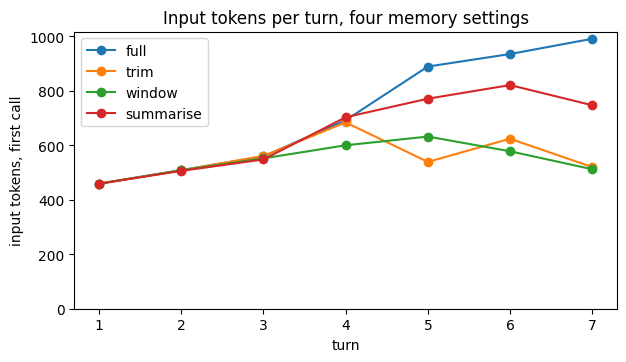

In [40]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.6))
for name, rows in SETTINGS:
    ax.plot([row["turn"] for row in rows], [row["first_input"] for row in rows], marker="o", label=name)
ax.set_ylim(0, None)
ax.set_xlabel("turn")
ax.set_ylabel("input tokens, first call")
ax.set_title("Input tokens per turn, four memory settings")
ax.legend()
plt.show()

Full history climbs every turn (459 to 991 in our run, `gpt-4o-mini`, 11 Oct 2026). Trim and window stay low and end close together (520 and 512). Summarise rises until the first summary at turn 4, then stays in a band and ends between the others (747).

The chart shows the first call of each turn only. The summariser's calls are extra, and so are the second calls after
a tool result. Add up every call in each setting.

In [41]:
for name, rows in SETTINGS:
    calls = [call for row in rows for call in row["calls"]]
    by_summariser = [call for call in calls if call["caller"] == "summariser"]
    total = sum(call["input_tokens"] for call in calls)
    cached = sum(call["cached"] for call in calls)
    print(f"{name:10} {len(calls):2} model calls ({len(by_summariser)} by the summariser), "
          f"{total:6} input tokens, {cached:5} cached")

full        9 model calls (0 by the summariser),   6460 input tokens,     0 cached
trim        9 model calls (0 by the summariser),   5168 input tokens,     0 cached
window     10 model calls (0 by the summariser),   5534 input tokens,     0 cached
summarise  12 model calls (3 by the summariser),   8271 input tokens,     0 cached


When we ran it (`gpt-4o-mini`, 11 Oct 2026):

| Setting | Model calls | By the summariser | Input tokens, all calls | Cached |
|---|---|---|---|---|
| full | 9 | 0 | 6,460 | 0 |
| trim | 9 | 0 | 5,168 | 0 |
| window | 10 | 0 | 5,534 | 0 |
| summarise | 12 | 3 | 8,271 | 0 |

Summarising used the **most** input tokens, more than full history. Its first calls were smaller, but each summary is a model call that is sent the messages it replaces. Four earlier runs with `gpt-4o-mini` on 10 Oct 2026 gave the same order (summarise 8,479, 8,517, 8,456 and 6,855 against full history's 6,749, 7,977, 6,342 and 6,352). Summarising pays off on long threads, where full history grows past what the summaries cost; on a short thread it is the expensive choice. The number of calls differs between settings because the copilot called `get_policy` a different number of times.

Nothing was cached. OpenAI caches a prompt automatically only from 1,024 tokens, and our largest call was 991. On a long thread, full history keeps the start of each request the same from call to call, so later calls can be served from the cache at half the input price for `gpt-4o-mini`; a summary rewrites the start of the request, and trimming moves it.

### Checkpoint C

Token counts move from run to run because the replies differ. Check the shapes and the order, not our exact numbers.

| You should see | Value from our run (`gpt-4o-mini`, 11 Oct 2026) |
|---|---|
| The log test | 1 call, 2 messages sent (459 input tokens) |
| Full history | the first-call input grows every turn (ours: 459 to 991) |
| Trim | stays in a narrow band (ours: 459 to 684) |
| Window | the same band as trim, but its saved thread keeps every message (ours: 459 to 632; 20 messages saved against trim's 4) |
| Summarise | rises until the first summary, then stays in a band (ours: 703 to 821 from turn 4), with extra summariser calls (ours: 3) |
| Turn 7, first call | full the highest, trim and window the lowest, summarise between (ours: 991, 520, 512 and 747) |
| All calls, seven turns | summarise the most input tokens, then full, then trim and window (ours: 8,271 with 3 summariser calls, 6,460, then window 5,534 and trim 5,168); 0 cached |

A reference run with `gpt-6-luna` (5 Oct 2026) had turn-7 inputs of 1,672, 625 and 870 for full, trim and summarise:
the same order. Compare with it if `models.env` names that model.

---

## Part D: Ask for an early fact at turn 7

Turn 7 asked for two facts that only turn 2 stated: the invoice total, $49.62, and the rep, Steve Johnson. A setting
passes when its turn-7 reply has both. We check with plain string tests.

In [42]:
FACTS = ["49.62", "Steve Johnson"]
for name, rows in SETTINGS:
    reply = rows[-1]["reply"]
    found = [fact for fact in FACTS if fact in reply]
    mark = "✅" if found == FACTS else "❌"
    print(f"{mark} {name:9} has {found}\n   {reply}\n")

✅ full      has ['49.62', 'Steve Johnson']
   Helena's invoice total is $49.62, and her assigned rep is Steve Johnson.

❌ trim      has []
   I'm unable to access customer-specific details like invoice totals or assigned representatives. Please check your system or database for that information.

❌ window    has []
   I don't have access to customer invoice totals or assigned representatives. Please check your internal system for that information.

✅ summarise has ['49.62', 'Steve Johnson']
   Helena Holý has 7 invoices totaling $49.62, with Steve Johnson as her assigned representative.



When we ran it (`gpt-4o-mini`, 11 Oct 2026), full history and summarise had both facts. Trim and window had neither; trim answered *I'm unable to access customer-specific details like invoice totals or assigned representatives. Please check your system or database for that information.* The `gpt-6-luna` reference run (5 Oct 2026) gave the same result for full, trim and summarise.

This is the planned dead end. The trimmed copilot ran without an error, its token counts were the lowest, and its reply
is polite and sounds reasonable. It is still wrong: the rep gave it the facts five turns earlier. Only a late
question about an early fact shows the problem. Look at what the trimmed thread still holds.

In [43]:
trim_state = trim_agent.get_state({"configurable": {"thread_id": "case-helena-trim"}}).values["messages"]
print(len(trim_state), "messages saved")
for message in trim_state:
    print(f"{message.type:5} | {message.text[:80]!r}")

window_state = window_agent.get_state({"configurable": {"thread_id": "case-helena-window"}}).values["messages"]
print()
print("window:", len(window_state), "messages saved; turn 2 still there:",
      any("49.62" in message.text for message in window_state))

4 messages saved
human | 'Draft a two-sentence reply I can send her.'
ai    | 'Sure! Here\'s a draft you can use: \n\n"Thank you for your patience as we review yo'
human | 'Before I close the ticket: what is her invoice total, and who is her assigned re'
ai    | "I'm unable to access customer-specific details like invoice totals or assigned r"

window: 20 messages saved; turn 2 still there: True


Trim has 4 messages saved: turns 6 and 7. Turn 2 is gone from the saved thread for good. Window still has all 20 messages, turn 2 included, but the model was sent only the newest six. Keeping the record is not the same as the model seeing it.

Summarising kept the facts in our run, but a summary is text written by a model, and it can drop or blur a number.
Read it before you trust it. The summary is the saved message marked `lc_source: "summarization"`.

In [44]:
summary_state = summary_agent.get_state({"configurable": {"thread_id": "case-helena-summarise"}}).values["messages"]
summary = [m for m in summary_state if m.additional_kwargs.get("lc_source") == "summarization"][0]
print(summary.text)

Here is a summary of the conversation to date:

## SESSION INTENT

The user's primary goal is to handle Helena Holý's emails, specifically addressing inquiries about invoices and policy related to a product issue.

## SUMMARY

Helena Holý has 7 invoices totaling $49.62, with Steve Johnson as her assigned representative. She reported an issue where the "Kind of Blue" sleeve contained a different disc inside. The user is seeking guidance on the policy regarding this matter and learned that there is no specific policy for defective products, leading them to consult the support manager. Helena expressed a preference for a replacement rather than a refund. An exchange is allowed within a 30-day unopened window, involving a new order. The user has suggested a reply to Helena regarding the exchange process.

## ARTIFACTS

None

## NEXT STEPS

Consult the support manager for guidance on providing a replacement for Helena Holý's defective product issue.


Find the line that kept, or lost, the two facts.

In [45]:
for line in summary.text.splitlines():
    if "49.62" in line or "Steve Johnson" in line:
        print(line)

Helena Holý has 7 invoices totaling $49.62, with Steve Johnson as her assigned representative. She reported an issue where the "Kind of Blue" sleeve contained a different disc inside. The user is seeking guidance on the policy regarding this matter and learned that there is no specific policy for defective products, leading them to consult the support manager. Helena expressed a preference for a replacement rather than a refund. An exchange is allowed within a 30-day unopened window, involving a new order. The user has suggested a reply to Helena regarding the exchange process.


When we ran it (`gpt-4o-mini`, 11 Oct 2026), the facts opened the `SUMMARY` section: *Helena Holý has 7 invoices totaling $49.62, with Steve Johnson as her assigned representative.* That line is why the summarising copilot could answer turn 7: the messages from turn 2 were no longer in the thread, but the summary that replaced them was. A summary written in another run can leave a fact out or round a number; only reading it tells you.

### Keep the case facts in state

Trimming lost the facts because they lived only in the conversation. In a real support tool they would not depend on
the rep typing them: when a case is opened, the system knows the customer and can read the record (Day 2 does this
with tools over the Ops API). So keep facts that must survive **outside the messages**, in the agent's state, and add
them to the prompt on every call. No trim or summary touches them. This is the fix for the dead end above.

First, a state with one more field. `AgentState` holds `messages`; `CaseState` adds `case_facts`, which the
checkpointer saves with the thread.

In [46]:
from langchain.agents import AgentState

class CaseState(AgentState):
    case_facts: str

Next, the prompt. `@dynamic_prompt` builds the system prompt for each call from the request, so it can read the state.
It replaces the `system_prompt=` argument, so it returns the whole prompt: v1 plus a `# Case` section.

In [47]:
from langchain.agents.middleware import ModelRequest, dynamic_prompt

@dynamic_prompt
def prompt_with_case(request: ModelRequest) -> str:
    facts = request.state.get("case_facts", "No case loaded.")
    return SYSTEM_PROMPT + "\n\n# Case\n" + facts

The facts come from the shop's records, `data/chinook.db`, with a query like the one in Lab 00, not from the rep's
message.

In [48]:
query = (
    "SELECT c.FirstName || ' ' || c.LastName, COUNT(i.InvoiceId), ROUND(SUM(i.Total), 2), "
    "e.FirstName || ' ' || e.LastName "
    "FROM customers c JOIN invoices i ON i.CustomerId = c.CustomerId "
    "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = 6"
)
chinook = sqlite3.connect(ROOT / "data" / "chinook.db")
name, invoices, total, rep = chinook.execute(query).fetchone()
chinook.close()
CASE_FACTS = f"Customer: {name} (customer 6). {invoices} invoices totalling ${total}. Assigned rep: {rep}."
print(CASE_FACTS)

Customer: Helena Holý (customer 6). 7 invoices totalling $49.62. Assigned rep: Steve Johnson.


Now the copilot: the `window` trim from Part C plus the case. Before turn 1, the code that opens the case writes the
facts into the thread's state with `update_state`, as Part A did when it deleted messages. Then the same seven turns.

In [49]:
case_agent = create_agent(chat_model(settings), tools=[get_policy], state_schema=CaseState,
                          middleware=[prompt_with_case, send_recent], checkpointer=InMemorySaver())
case_agent.update_state({"configurable": {"thread_id": "case-helena-state"}}, {"case_facts": CASE_FACTS})
with_case = run_turns(case_agent, "case-helena-state", TURNS)

turn 1: first call sent  2 messages,  488 input tokens | model calls: 1 (0 by the summariser)


turn 2: first call sent  4 messages,  534 input tokens | model calls: 1 (0 by the summariser)


turn 3: first call sent  6 messages,  587 input tokens | model calls: 2 (0 by the summariser)


turn 4: first call sent  6 messages,  693 input tokens | model calls: 1 (0 by the summariser)


turn 5: first call sent  4 messages,  529 input tokens | model calls: 1 (0 by the summariser)


turn 6: first call sent  6 messages,  580 input tokens | model calls: 1 (0 by the summariser)


turn 7: first call sent  6 messages,  588 input tokens | model calls: 1 (0 by the summariser)


Check turn 7, and the cost over all calls.

In [50]:
reply = with_case[-1]["reply"]
found = [fact for fact in FACTS if fact in reply]
print("✅" if found == FACTS else "❌", found, "|", reply)
calls = [call for row in with_case for call in row["calls"]]
print(len(calls), "model calls,", sum(call["input_tokens"] for call in calls), "input tokens")

✅ ['49.62', 'Steve Johnson'] | The customer has a total of $49.62 in invoices, and her assigned rep is Steve Johnson.
8 model calls, 4664 input tokens


When we ran it (`gpt-4o-mini`, 11 Oct 2026), the case-state copilot answered turn 7 with both facts: *The customer has a total of $49.62 in invoices, and her assigned rep is Steve Johnson.* It used 8 model calls and 4,664 input tokens over the seven turns, less than full history's 6,460 and less than trim's 5,168 (it called `get_policy` less often), although every call carried the case section (turn 1 sent 488 tokens against 459 without it). An earlier run (10 Oct 2026) used 10 calls and 5,837 tokens. The window still trimmed the conversation; the facts that matter were never in it.

What to use when:

| The conversation | Use |
|---|---|
| short | full history |
| long, and nothing said early must survive | a transient trim (`window`) |
| long, with facts that must survive | case facts in state, plus a trim or a summary for the rest |
| holds data that must be removed | a persistent trim or a delete |
| very long, and the gist matters | summarising with a token trigger; read the summary |

Facts in state must be right and current: if the rep corrects one, your code updates the state (the Challenge lets the copilot do it with a tool). Day 2 goes further and looks the record up with a tool when it is needed (Lab 07).

### Checkpoint D

| You should see | Value from our run (`gpt-4o-mini`, 11 Oct 2026) |
|---|---|
| Full history, turn 7 | both facts |
| Trim, turn 7 | neither fact (ours: *I'm unable to access customer-specific details like invoice totals ...*) |
| Window, turn 7 | neither fact; turn 2 is still in its saved thread, but the model was not sent it |
| Summarise, turn 7 | both facts |
| The trimmed thread | turn 2 is not in it |
| The summary | the `SUMMARY` section opens with $49.62 and Steve Johnson |
| Case facts in state | `Customer: Helena Holý (customer 6). 7 invoices totalling $49.62. Assigned rep: Steve Johnson.`; turn 7 has both facts, at close to trim's cost (ours: 4,664 input tokens against trim's 5,168 and full history's 6,460) |

A summarising run that loses a fact is a valid result, not a mistake in your code: it is the risk of summarising.
Write down which fact it lost and the summary line that should have held it.

---

## Part E: Choose a memory strategy

Work on paper. For each conversation below:

1. choose full history, trim or summarise;
2. name one fact your choice could lose;
3. write the question that would test for it.

Ask yourself: does a late turn depend on a fact stated early?

| # | Conversation |
|---|---|
| 1 | Three turns about shipping times to Canada. |
| 2 | A 40-turn refund dispute; the invoice number was given in turn 2. |
| 3 | One rep, one all-day chat, 25 unrelated customer questions. |

Bonus: for the long case, pick `trigger` and `keep` values to start with.

Write your answers before you read on.

### Check your answers

| # | Choose | Could lose | Test with |
|---|---|---|---|
| 1 | full history | nothing: it is short | not needed |
| 2 | the invoice number in the case state; full history, then summarising once the thread gets long | the exact invoice number, if it lives only in the messages | turn 40: "Which invoice?" |
| 3 | a thread per customer, or trim | earlier customers (which you want) | "Who was my first customer?" |

Bonus, a starting point for a message trigger: `trigger=("messages", 30)` and `keep=("messages", 10)`, then test
with the turn-40 question. Part C used 8 and 4 so that seven turns would show the summary; it summarised three times in seven
turns, which a 40-turn thread would multiply.

A common mistake is to summarise everything, including case 3:

| Case 3 option | Extra cost | Risk |
|---|---|---|
| summarise all day | a model call at each trigger | customers blur together |
| new thread per customer | none | none: each case starts clean |

A new `thread_id` per customer costs nothing and keeps each case separate, as Part A showed with `case-puja-01`.

### Case 2: keep the invoice number in the case state

Summarising alone could keep the invoice number, and it could also blur it. Put the number in the case state, as at
the end of Part D, so that no memory setting can lose it, and keep full history while the thread is far from the
model's limit. At the growth we measured, about 90 input tokens per turn on average (459 to 991 over six turns, `gpt-4o-mini`,
11 Oct 2026), turn 40 would send roughly 4,000 input tokens, about 3% of `gpt-4o-mini`'s 128,000-token context
window: an estimate, not a run. Add
summarising with a token trigger when threads do get near the budget, or when the volume of conversations makes
every token count. The test question stays the same: ask "Which invoice?" at turn 40.

### Checkpoint E

| You should see | Value |
|---|---|
| Your table | a choice, a fact it could lose and a test question for each conversation |
| Case 2 | the invoice number kept where no setting can lose it (summary or, better, case state); tested by a late "Which invoice?" |
| Case 3 | a thread per customer (or trim), not one summarised all-day thread |

## What you can do now

- Give an agent thread memory with a checkpointer and a `thread_id`, and say what the model receives on each turn.
- Keep a thread in a SQLite file with `SqliteSaver` and read it back from a new connection.
- Trim to a message count or a token budget with `trim_messages`, and delete named messages with `RemoveMessage`.
- Choose between a persistent trim (`before_model`, the saved thread shrinks) and a transient one (`wrap_model_call`,
  only the request shrinks).
- Keep facts that must survive in the agent's state and add them to the prompt with `@dynamic_prompt`.
- Summarise older turns with `SummarizationMiddleware`, and read the saved summary before trusting it.
- Log every model call of a turn with a callback handler and compare settings by input tokens and model calls.
- Choose full history, trimming, summarising or a new thread for a conversation, and test the choice with a late
  question about an early fact.

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, ...` | `invoke` was called without the config | pass `{"configurable": {"thread_id": "..."}}` as the second argument |
| The agent forgets the previous turn | no `checkpointer=` in `create_agent`, or a different `thread_id` on each call | add the checkpointer; reuse the same config dictionary for the whole conversation |
| A reply mentions another customer | two cases share one `thread_id` | one `thread_id` per case |
| `sqlite3.ProgrammingError: SQLite objects created in a thread can only be used in that same thread` | the connection was opened without `check_same_thread=False` | `sqlite3.connect(db_file, check_same_thread=False)` |
| `sqlite3.ProgrammingError: Cannot operate on a closed database.` | an agent was used after `conn.close()` | open a new connection and build a new agent on it, as Part B does |
| `ModuleNotFoundError: No module named 'langgraph.checkpoint.sqlite'` or `'matplotlib'` | the packages were not installed from `requirements.txt` | run the setup cell (Colab) or `uv sync` (local), then restart the kernel |
| `BadRequestError` 400, `No tool output found for function call call_...` | a trim or delete removed a tool result but kept the tool call that asked for it | trim with `start_on="human"`, and delete a tool call together with its tool message |
| No summariser calls in Part C | the thread never reached the `trigger` | count the saved messages; lower the trigger or run more turns |
| The case-state copilot ignores the case facts | the agent was built without `state_schema=CaseState` or without `prompt_with_case` in `middleware`, or `update_state` ran on another `thread_id` | rebuild it as in Part D and run `update_state` with the same config before turn 1 |
| A `system_prompt=` you passed has no effect | `@dynamic_prompt` replaces it on every call | put the whole prompt in the dynamic prompt function |
| `cached` is 0 everywhere | OpenAI caches only prompts of 1,024 tokens or more, and only a prefix it has seen recently | expected in this lab; long threads with a stable start get cache hits |
| Your token counts or replies differ from ours | model replies change from run to run | compare the shapes, the order and the two facts at turn 7 |
| `OpenAIError: Missing credentials` or `AuthenticationError` | no key, or a wrong one | see Lab 00's troubleshooting table; then run the config cell again |
| `RateLimitError` | a shared class key reached its limit | wait a minute and run the cell again; tell the instructor if it repeats |

## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor. Each task reuses `get_policy`,
`CallLog`, `run_turns` and `SYSTEM_PROMPT` from Part C.

1. **Let the copilot save a case fact itself.** In Part D your code wrote the case facts. Write a tool,
   `note_case_fact(fact: str, runtime: ToolRuntime) -> Command`, that adds one line to `case_facts` and returns
   `Command(update={"case_facts": ..., "messages": [ToolMessage("Saved.", tool_call_id=runtime.tool_call_id)]})`
   (`ToolRuntime` from `langchain.tools`, `Command` from `langgraph.types`; the docs' "Write short-term memory from
   tools"). Give it to the case-state copilot with no facts loaded, add one line to the prompt telling it to save facts
   the rep states about the customer, and run the seven turns. Expected: the model saves facts without being asked once the prompt tells it to. In our three runs (`gpt-4o-mini`, 10 Oct 2026) it saved three notes (the name, *7 invoices totalling $49.62*, the rep) and answered turn 7 correctly with the window trim on. It sometimes calls the tool twice in one step (parallel tool calls); a plain `str` field then stops the run with `InvalidUpdateError: At key 'case_facts': Can receive only one value per step`. Declare the field as a list with a reducer, `Annotated[list[str], operator.add]`, so both notes are added.
2. **A message trigger on a longer thread.** Build a summarising agent with `trigger=("messages", 30)` and
   `keep=("messages", 10)`. Write a 12-turn thread in which turn 2 says Helena is disputing invoice 404 (13 November
   2013, $25.86, from `data/chinook.db`) and the last turn asks *"Which invoice is she disputing, and what was its
   total?"* Count the summariser calls and read the summary if there is one; if there is none, find out why. Expected: the summary is written only when the saved thread holds 30 messages before a model call. In four runs (`gpt-4o-mini`, 10 Oct 2026) the 12-turn thread summarised once in two and not at all in the other two (29 messages before the last call); every last reply gave invoice 404 and $25.86. If you see no summary, ask turns 3 to 11 again before the last question (21 turns) on a new `thread_id`: ours summarised twice, kept the invoice number and total on a summary line, and answered correctly. Quote that line.
3. **A thread per customer.** Run two short cases, Helena Holý and then Puja Srivastava (6 invoices totalling
   $36.64, rep Jane Peacock), first on one all-day thread and then on one thread each. In both set-ups, end each case
   with *"What is this customer's invoice total?"*, then ask Puja's thread *"Who was my first customer today?"*.
   Expected: both set-ups give each customer's own total ($49.62 and $36.64). On the all-day thread the model also names the first customer, Helena Holý; on Puja's own thread it cannot, which is what you want. The difference is cost and risk: the all-day thread's last call carried Helena's case too (883 input tokens against 792 on Puja's own thread, in our run with `gpt-4o-mini` on 10 Oct 2026), and after 25 customers it would carry 24 other cases. Say which set-up you would recommend for an all-day rep, and why.

## Resources

- [LangChain: short-term memory](https://docs.langchain.com/oss/python/langchain/short-term-memory): checkpointers, `thread_id`, trimming, deleting and summarising in an agent
- [LangChain: built-in middleware](https://docs.langchain.com/oss/python/langchain/middleware/built-in): `SummarizationMiddleware` and its `trigger` and `keep` settings
- [LangChain: context engineering](https://docs.langchain.com/oss/python/langchain/context-engineering): transient (`wrap_model_call`) and persistent (`before_model`, summarisation) changes to what the model sees
- [OpenAI: prompt caching](https://developers.openai.com/api/docs/guides/prompt-caching): when input tokens are cached and what that saves
- [LangChain: custom middleware](https://docs.langchain.com/oss/python/langchain/middleware/custom): `before_model`, `wrap_model_call` and `@dynamic_prompt`
- [LangChain: messages](https://docs.langchain.com/oss/python/langchain/messages): message types, their content and ids
- [LangGraph: persistence](https://docs.langchain.com/oss/python/langgraph/persistence): threads, checkpoints and the checkpointer libraries, SQLite and Postgres included
- [`langgraph-checkpoint-sqlite` on PyPI](https://pypi.org/project/langgraph-checkpoint-sqlite/): the SQLite saver
- [LangChain: memory concepts](https://docs.langchain.com/oss/python/concepts/memory): short-term memory (this lab) and long-term memory ([Lab 04](../04_Long_Term_Memory_And_Privacy/README.md))
- [OpenAI: conversation state](https://developers.openai.com/api/docs/guides/conversation-state): why each request is stateless, and the provider-side options for keeping a conversation